# From correlation to angular distance

The first distance treats negative correlation as far apart, while the second treats equal positive and negative correlations as equally close:

$$
d_{\rho}(X,Y)=\sqrt{\frac{1-\rho(X,Y)}{2}},
\qquad
d_{|\rho|}(X,Y)=\sqrt{\frac{1-|\rho(X,Y)|}{2}}.
$$

Here, $X$ and $Y$ are paired return series; $\rho(X,Y)\in[-1,1]$ is their sample correlation. $d_{\rho}$ is angular distance; $d_{|\rho|}$ is distance based on absolute correlation; $|\cdot|$ is absolute value.

In [1]:
import re as _table_number_re
from IPython.display import HTML as _TableHTML, display as _raw_display

def compact_float_format(number_format=None):

    def format_value(value):
        if number_format is None:
            rendered = str(value)
        elif callable(number_format):
            rendered = str(number_format(value))
        else:
            rendered = number_format % value
        return compact_numeric_token(rendered)
    return format_value

def compact_numeric_token(rendered):
    if not _table_number_re.fullmatch('[+-]?(?:[0-9]+(?:\\.[0-9]*)?|\\.[0-9]+)(?:[eE][+-]?[0-9]+)?', rendered):
        return rendered
    value = float(rendered)
    if value != 0.0 and abs(value) < 5e-13:
        return '0'
    if ('.' in rendered or 'e' in rendered.lower()) and value.is_integer():
        return str(int(value))
    return rendered

def compact_numeric_text(text):
    pattern = '(?<![0-9.eE])([+-]?(?:[0-9]+(?:\\.[0-9]*)?|\\.[0-9]+)(?:[eE][+-]?[0-9]+)?)(?![0-9.eE])'
    return _table_number_re.sub(pattern, lambda match: compact_numeric_token(match.group(0)), text)

def compact_table_latex(latex):
    return compact_numeric_text(latex)

def _compact_table_html(value):
    frame = value.to_frame() if isinstance(value, pd.Series) else value
    html = frame._repr_html_()
    return '<div style="display:flex;justify-content:center;">' + compact_numeric_text(html) + '</div>'

def display(value):
    if isinstance(value, (pd.DataFrame, pd.Series)):
        return _raw_display(_TableHTML(_compact_table_html(value)))
    return _raw_display(value)
from pathlib import Path
import sys
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.stats as ss
from IPython.display import Image
from sklearn.metrics import mutual_info_score
ROOT = Path.cwd().parents[1]
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from book_support import ensure_dataset
DATA_URL = 'https://data.binance.vision/data/spot/monthly/klines/BTCUSDT/1m/BTCUSDT-1m-2021-01.zip'
DATA_DIR = ROOT / 'data' / 'public' / 'binance'
DATA_PATH = ensure_dataset(ROOT, 'binance_btcusdt')
DATA_DIR.mkdir(parents=True, exist_ok=True)
assert DATA_PATH.is_file()
public_columns = ['Open time', 'Open', 'High', 'Low', 'Close', 'Volume', 'Close time', 'Quote volume', 'Trades', 'Buyer base volume', 'Buyer quote volume', 'Unused']
raw = pd.read_csv(DATA_PATH, compression='zip', header=None, names=public_columns, nrows=None)
raw['time'] = pd.to_datetime(raw['Open time'], unit='ms', utc=True).dt.tz_convert(None)
raw = raw.rename(columns={'Close': 'close', 'Volume': 'volume', 'Quote volume': 'quote_volume', 'Trades': 'trades'})
raw = raw.sort_values('time').drop_duplicates('time').reset_index(drop=True)
from RiskLabAI.data.distance import distance_correlation, ksg_mutual_information
from RiskLabAI.data.distance.distance_metric import calculate_distance, calculate_mutual_information, calculate_number_of_bins, calculate_variation_of_information, calculate_variation_of_information_extended
from RiskLabAI.features.entropy_features import grassberger_entropy, miller_madow_entropy, nsb_entropy
from RiskLabAI.features.entropy_features.kontoyiannis import kontoyiannis_entropy
from RiskLabAI.features.entropy_features.lempel_ziv import lempel_ziv_entropy
from RiskLabAI.features.entropy_features.plug_in import plug_in_entropy_estimator
from RiskLabAI.features.entropy_features.pmf import probability_mass_function
from RiskLabAI.features.entropy_features.shannon import shannon_entropy
FIGURES = ROOT / 'outputs' / 'figures' / '09_dependence_geometry_information'
TABLES = ROOT / 'outputs' / 'tables' / '09_dependence_geometry_information'
FIGURES.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)
palette = {'background': '#111827', 'axes': '#111827', 'text': '#E5E7EB', 'cyan': '#38BDF8', 'amber': '#FBBF24', 'green': '#34D399', 'rose': '#FB7185', 'violet': '#C084FC', 'grid': '#374151'}
plt.rcParams.update({'font.family': 'Times New Roman', 'font.size': 11.5, 'figure.facecolor': palette['background'], 'axes.facecolor': palette['axes'], 'axes.edgecolor': palette['text'], 'axes.labelcolor': palette['text'], 'axes.titlecolor': palette['text'], 'xtick.color': palette['text'], 'ytick.color': palette['text'], 'text.color': palette['text'], 'grid.color': palette['grid'], 'grid.linestyle': ':', 'legend.facecolor': palette['axes'], 'legend.edgecolor': palette['grid'], 'savefig.facecolor': palette['background']})

def save_table(frame, stem, caption, label, float_format='%.6f', fit=True):
    frame.to_csv(TABLES / f'{stem}.csv', index=False)
    latex = compact_table_latex(frame.to_latex(index=False, escape=True, float_format=compact_float_format(float_format), caption=caption, label=label, position='H'))
    if fit:
        latex = latex.replace('\\begin{tabular}', '\\begin{adjustbox}{max width=\\textwidth}\\begin{tabular}', 1).replace('\\end{tabular}', '\\end{tabular}\\end{adjustbox}', 1)
    else:
        latex = latex.replace('\\begin{tabular}', '\\centering\n' + '\\begin{tabular}', 1)
    (TABLES / f'{stem}.tex').write_text(latex, encoding='utf-8')
raw = raw.sort_values('time').dropna(subset=['time', 'close']).drop_duplicates('time').reset_index(drop=True)
minute_close = pd.Series(raw['close'].to_numpy(dtype=float), index=pd.DatetimeIndex(raw['time']), name='One-minute close')
close = minute_close.resample('15min').last().dropna().rename('Fifteen-minute close')
log_price = np.log(close).rename('Log price')
returns = log_price.diff().dropna().rename('Fifteen-minute log return')
plt.rcParams.update({'font.family': 'Times New Roman', 'font.size': 11.5, 'figure.facecolor': '#111827', 'axes.facecolor': '#111827', 'axes.edgecolor': '#94A3B8', 'axes.labelcolor': '#E5E7EB', 'axes.titlecolor': '#E5E7EB', 'axes.titleweight': 'bold', 'xtick.color': '#94A3B8', 'ytick.color': '#94A3B8', 'text.color': '#E5E7EB', 'grid.color': '#374151', 'grid.linestyle': ':', 'grid.linewidth': 0.8, 'legend.facecolor': '#111827', 'legend.edgecolor': '#374151', 'legend.framealpha': 0.96, 'savefig.facecolor': '#111827', 'savefig.transparent': False, 'savefig.dpi': 300, 'pdf.fonttype': 42, 'ps.fonttype': 42})
import RiskLabAI as _risklabai_release
assert _risklabai_release.__version__ == '3.2.0'


## Distances from Public Returns

In [2]:
data_provenance = pd.DataFrame({'Field': ['Archive', 'Provider', 'Public access', 'Market', 'Minute records', 'Analysis interval', 'Analysis records', 'Return observations', 'First analysis time', 'Last analysis time'], 'Value': ['BTCUSDT-1m-2021-01.zip', 'Binance Data Vision', 'Direct public download', 'Bitcoin quoted in USDT', f'{len(minute_close):,}', 'Fifteen minutes', f'{len(close):,}', f'{len(returns):,}', str(close.index.min()), str(close.index.max())]})
feature_frame = pd.DataFrame({'One-interval return': log_price.diff(1), 'Two-interval return': log_price.diff(2), 'Four-interval return': log_price.diff(4), 'Eight-interval return': log_price.diff(8), 'Negative one-interval return': -log_price.diff(1)}).dropna()
correlation = feature_frame.corr()
angular = pd.DataFrame(calculate_distance(correlation.to_numpy(), metric='angular'), index=correlation.index, columns=correlation.columns)
absolute_angular = pd.DataFrame(calculate_distance(correlation.to_numpy(), metric='absolute_angular'), index=correlation.index, columns=correlation.columns)
pair_rows = []
names = list(correlation.columns)
for left in range(len(names)):
    for right in range(left + 1, len(names)):
        pair_rows.append({'Pair': f'{names[left]} and {names[right]}', 'Correlation': correlation.iloc[left, right], 'Angular distance': angular.iloc[left, right], 'Absolute-correlation distance': absolute_angular.iloc[left, right]})
correlation_distance_pairs = pd.DataFrame(pair_rows)
save_table(data_provenance, 'data_provenance', 'Public data used in Chapter 8.', 'tab:chapter8-data-provenance', fit=True)
save_table(correlation_distance_pairs, 'correlation_distance_pairs', 'Correlation and its two distance transformations for public return pairs.', 'tab:chapter8-correlation-distance-pairs', fit=True)
display(data_provenance)
display(correlation_distance_pairs.round(6))


,Field,Value
0,Archive,BTCUSDT-1m-2021-1zip
1,Provider,Binance Data Vision
2,Public access,Direct public download
3,Market,Bitcoin quoted in USDT
4,Minute records,"44,640"
5,Analysis interval,Fifteen minutes
6,Analysis records,"2,976"
7,Return observations,"2,975"
8,First analysis time,2021-01-01 00:00:00
9,Last analysis time,2021-01-31 23:45:00


,Pair,Correlation,Angular distance,Absolute-correlation distance
0,One-interval return and Two-interval return,0.698595,0.388204,0.388204
1,One-interval return and Four-interval return,0.476032,0.511844,0.511844
2,One-interval return and Eight-interval return,0.324257,0.581267,0.581267
3,One-interval return and Negative one-interval ...,-1,1,0
4,Two-interval return and Four-interval return,0.685822,0.396345,0.396345
5,Two-interval return and Eight-interval return,0.474392,0.512644,0.512644
6,Two-interval return and Negative one-interval ...,-0.698595,0.921573,0.388204
7,Four-interval return and Eight-interval return,0.686467,0.395937,0.395937
8,Four-interval return and Negative one-interval...,-0.476032,0.859079,0.511844
9,Eight-interval return and Negative one-interva...,-0.324257,0.813713,0.581267


## Euclidean Geometry

Angular distance is a scaled Euclidean distance between centered and standardized observations:

$$
z_{X,t}=\frac{X_t-\overline X}{s_X},
\qquad
d_{\rho}(X,Y)=\frac{\lVert z_X-z_Y\rVert_2}{2\sqrt{N}}.
$$

Here, $X_t$ is observation $t$; $\overline X$ is the sample mean; $s_X$ is the population-form sample standard deviation. $z_X$ and $z_Y$ are standardized vectors; $N$ is their common length; $\lVert\cdot\rVert_2$ is Euclidean length.

In [3]:
standardized = (feature_frame - feature_frame.mean()) / feature_frame.std(ddof=0)
euclidean_scaled = np.zeros_like(correlation.to_numpy())
sign_free_scaled = np.zeros_like(correlation.to_numpy())
for left in range(len(names)):
    for right in range(len(names)):
        x = standardized.iloc[:, left].to_numpy()
        y = standardized.iloc[:, right].to_numpy()
        euclidean_scaled[left, right] = np.linalg.norm(x - y) / (2 * np.sqrt(len(x)))
        sign_free_scaled[left, right] = min(np.linalg.norm(x - y), np.linalg.norm(x + y)) / (2 * np.sqrt(len(x)))
metric_rows = []
for label, matrix, geometric in [("Angular distance", angular.to_numpy(), euclidean_scaled), ("Absolute-correlation distance", absolute_angular.to_numpy(), sign_free_scaled)]:
    triangle_excess = max(matrix[i, k] - matrix[i, j] - matrix[j, k] for i in range(len(names)) for j in range(len(names)) for k in range(len(names)))
    metric_rows.append({"Distance": label, "Largest diagonal value": np.max(np.abs(np.diag(matrix))), "Largest symmetry difference": np.max(np.abs(matrix - matrix.T)), "Largest triangle excess": triangle_excess, "Largest geometric difference": np.max(np.abs(matrix - geometric))})
distance_metric_checks = pd.DataFrame(metric_rows)
save_table(distance_metric_checks, "distance_metric_checks", "Numerical checks of distance properties and geometric identities.", "tab:chapter8-distance-metric-checks", fit=True)
display(distance_metric_checks)

,Distance,Largest diagonal value,Largest symmetry difference,Largest triangle excess,Largest geometric difference
0,Angular distance,0,0,0,3.214954e-07
1,Absolute-correlation distance,0,0,0,3.214954e-07


## Understanding the angular-distance scale

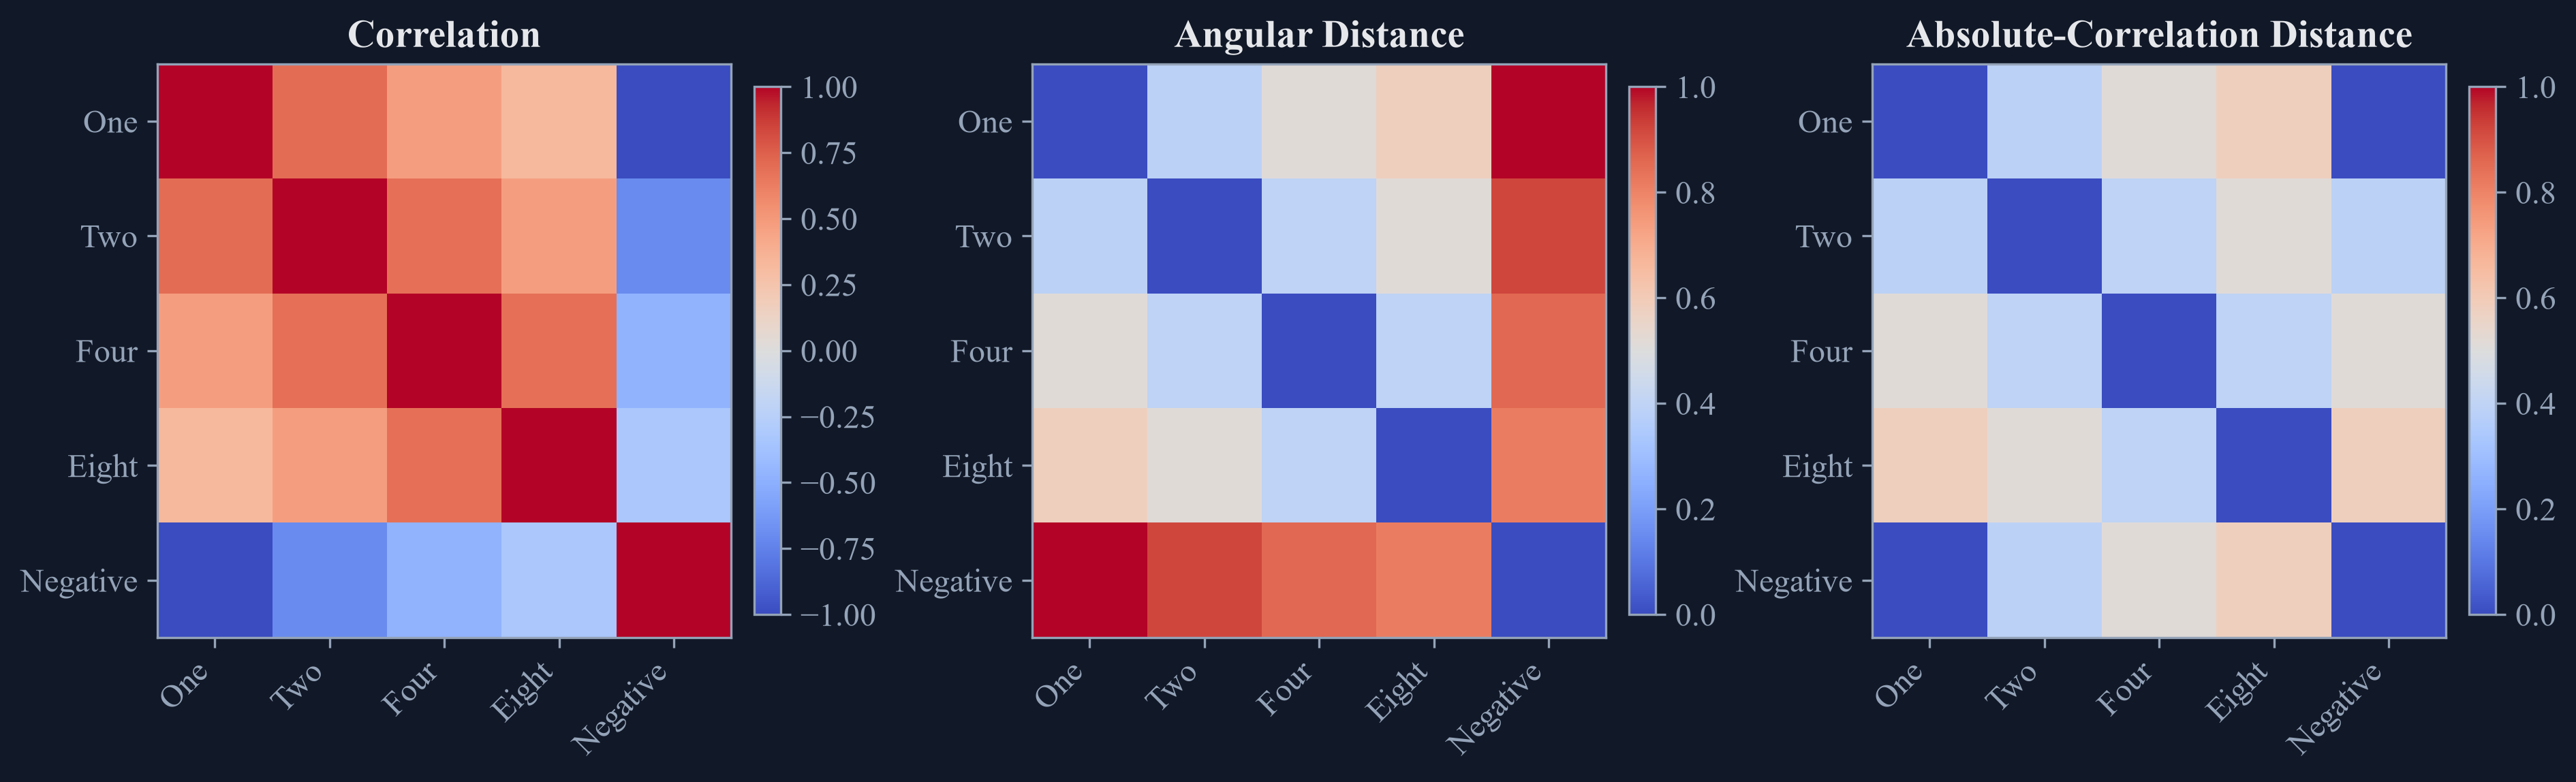

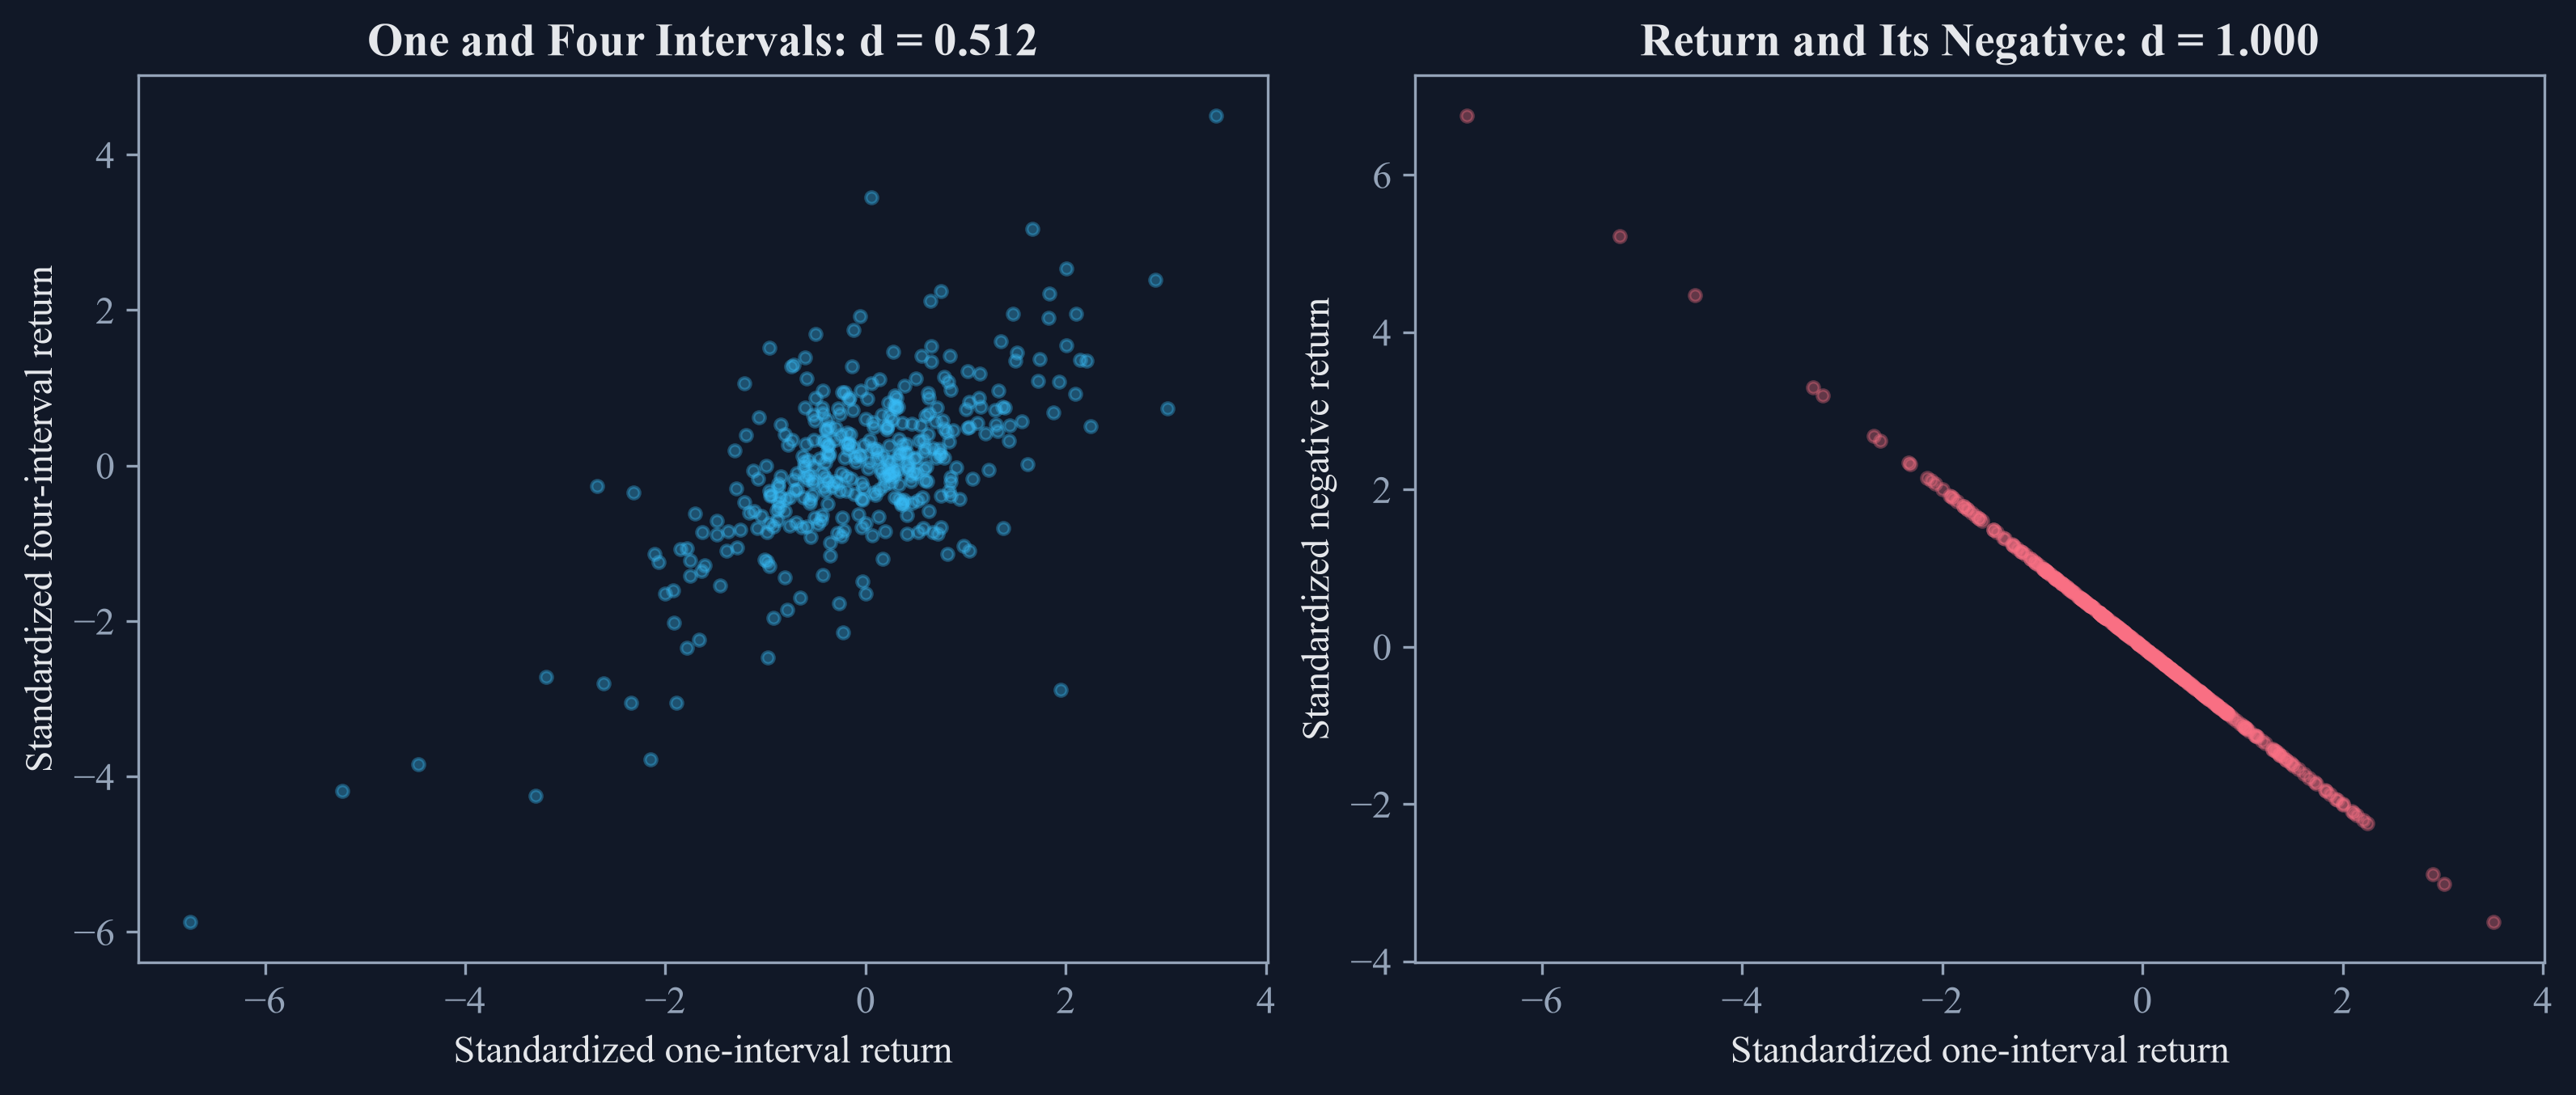

In [4]:
figure, axes = plt.subplots(1, 3, figsize=(12.5, 4.25), constrained_layout=True)
matrices = [(correlation, "Correlation", -1.0, 1.0), (angular, "Angular Distance", 0.0, 1.0), (absolute_angular, "Absolute-Correlation Distance", 0.0, 1.0)]
short_names = ["One", "Two", "Four", "Eight", "Negative"]
for axis, (matrix, title, lower, upper) in zip(axes, matrices):
    image = axis.imshow(matrix.to_numpy(), cmap="coolwarm", vmin=lower, vmax=upper)
    axis.set_xticks(range(len(short_names)), short_names, rotation=45, ha="right")
    axis.set_yticks(range(len(short_names)), short_names)
    axis.set_title(title)
    figure.colorbar(image, ax=axis, fraction=0.046, pad=0.04)
figure.savefig(FIGURES / "correlation_distance_matrices.png", bbox_inches="tight", dpi=300)
figure.savefig(FIGURES / "correlation_distance_matrices.pdf", bbox_inches="tight")
display(Image(filename=str(FIGURES / "correlation_distance_matrices.png")))
plt.close(figure)

figure, axes = plt.subplots(1, 2, figsize=(10.5, 4.4), constrained_layout=True)
sample = standardized.iloc[::8]
axes[0].scatter(sample["One-interval return"], sample["Four-interval return"], s=12, alpha=0.35, color=palette["cyan"])
axes[0].set_title(f"One and Four Intervals: d = {angular.loc['One-interval return', 'Four-interval return']:.3f}")
axes[0].set_xlabel("Standardized one-interval return")
axes[0].set_ylabel("Standardized four-interval return")
axes[1].scatter(sample["One-interval return"], sample["Negative one-interval return"], s=12, alpha=0.35, color=palette["rose"])
axes[1].set_title(f"Return and Its Negative: d = {angular.loc['One-interval return', 'Negative one-interval return']:.3f}")
axes[1].set_xlabel("Standardized one-interval return")
axes[1].set_ylabel("Standardized negative return")
figure.savefig(FIGURES / "standardized_geometry.png", bbox_inches="tight", dpi=300)
figure.savefig(FIGURES / "standardized_geometry.pdf", bbox_inches="tight")
display(Image(filename=str(FIGURES / "standardized_geometry.png")))
plt.close(figure)

## Tests

In [5]:
assert len(minute_close) == 44640
assert len(close) == 2976
assert len(returns) == 2975
assert len(feature_frame) == 2968
assert np.allclose(np.diag(correlation), 1.0)
assert np.allclose(np.diag(angular), 0.0)
assert np.allclose(np.diag(absolute_angular), 0.0)
assert np.allclose(angular, angular.T)
assert np.allclose(absolute_angular, absolute_angular.T)
assert np.max(np.abs(angular.to_numpy() - euclidean_scaled)) < 5e-07
assert np.max(np.abs(absolute_angular.to_numpy() - sign_free_scaled)) < 5e-07
assert distance_metric_checks['Largest triangle excess'].max() < 1e-12
assert np.isclose(correlation.loc['One-interval return', 'Negative one-interval return'], -1.0)
assert np.isclose(angular.loc['One-interval return', 'Negative one-interval return'], 1.0)
assert np.isclose(absolute_angular.loc['One-interval return', 'Negative one-interval return'], 0.0)
assert (FIGURES / 'correlation_distance_matrices.pdf').is_file()
assert (FIGURES / 'standardized_geometry.pdf').is_file()
